In [13]:
from google.colab import drive
drive.mount("/content/drive")

import sys, pandas as pd, numpy as np
import matplotlib.pyplot as plt

PROJECT = "/content/drive/MyDrive/traffic-project"
sys.path.insert(0, f"{PROJECT}/src")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
raw = pd.read_csv(f"{PROJECT}/data/Metro_Interstate_Traffic_Volume.csv")
raw["date_time"] = pd.to_datetime(raw["date_time"])

print("Rows:", len(raw))
print("Range:", raw["date_time"].min(), "to", raw["date_time"].max())
print("Duplicate timestamps:", raw["date_time"].duplicated().sum())
print("Missing values:\n", raw.isna().sum())
print("temp <= 0:", (raw["temp"] <= 0).sum(), "| max rain:", raw["rain_1h"].max())
raw.describe()

Rows: 48204
Range: 2012-10-02 09:00:00 to 2018-09-30 23:00:00
Duplicate timestamps: 7629
Missing values:
 holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
traffic_volume             0
dtype: int64
temp <= 0: 10 | max rain: 9831.3


,temp,rain_1h,snow_1h,clouds_all,date_time,traffic_volume
count,48204.000000,48204.000000,48204.000000,48204.000000,48204,48204.000000
mean,281.205870,0.334264,0.000222,49.362231,2016-01-05 10:46:16.773711616,3259.818355
min,0.000000,0.000000,0.000000,0.000000,2012-10-02 09:00:00,0.000000
25%,272.160000,0.000000,0.000000,1.000000,2014-02-06 11:45:00,1193.000000
50%,282.450000,0.000000,0.000000,64.000000,2016-06-11 03:30:00,3380.000000
75%,291.806000,0.000000,0.000000,90.000000,2017-08-11 06:00:00,4933.000000
max,310.070000,9831.300000,0.510000,100.000000,2018-09-30 23:00:00,7280.000000
std,13.338232,44.789133,0.008168,39.015750,NaN,1986.860670


In [10]:
%%writefile /content/drive/MyDrive/traffic-project/src/preprocessing.py
import numpy as np
import pandas as pd

NUM = ["traffic_volume", "temp_k", "rain_1h", "snow_1h", "clouds_all"]
WEATHER = ["weather_main", "weather_description"]

def clean_traffic_data(df, max_gap=6):
    df = df.rename(columns={"date_time": "timestamp", "temp": "temp_k"})
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    df["holiday"] = df["holiday"].fillna("None")      # "None" is read as NaN by pandas
    df = df.drop_duplicates("timestamp").sort_values("timestamp").set_index("timestamp")

    df.loc[df["temp_k"] <= 0, "temp_k"] = np.nan
    df.loc[df["rain_1h"] > 500, "rain_1h"] = np.nan

    df = df.asfreq("h")
    df["is_imputed"] = df[NUM].isna().any(axis=1).astype(int)

    missing = df["traffic_volume"].isna()
    gap_size = missing.groupby((~missing).cumsum()).transform("sum")
    df = df[~(missing & (gap_size > max_gap))]

    df[NUM] = df[NUM].interpolate(method="time")
    df[WEATHER] = df[WEATHER].ffill()
    df["holiday"] = df["holiday"].fillna("None")      # filled hours are not holidays
    df = df.dropna()
    df["traffic_volume"] = df["traffic_volume"].round().astype(int)
    df["clouds_all"] = df["clouds_all"].round().astype(int)
    return df

def add_features(df):
    out = df.copy()
    out["hour"] = out.index.hour
    out["dayofweek"] = out.index.dayofweek
    out["month"] = out.index.month
    tv = df["traffic_volume"].asfreq("h")             # full grid: NaN where gaps were dropped
    for lag in (1, 24, 168):
        out[f"lag_{lag}"] = tv.shift(lag).reindex(out.index)
    past = tv.shift(1)
    out["ma_24"] = past.rolling(24).mean().reindex(out.index)
    out["ma_168"] = past.rolling(168).mean().reindex(out.index)
    out["is_holiday"] = (out["holiday"] != "None").groupby(out.index.date).transform("max").astype(int)
    return out

Overwriting /content/drive/MyDrive/traffic-project/src/preprocessing.py


In [11]:
import importlib, preprocessing
importlib.reload(preprocessing)
from preprocessing import clean_traffic_data, add_features

clean = clean_traffic_data(raw)
clean.to_csv(f"{PROJECT}/data/traffic_clean.csv")

print("Rows before:", len(raw), "| after:", len(clean))
print("Imputed rows:", clean["is_imputed"].sum())
print("Holiday values:\n", clean["holiday"].value_counts().head())
print("Biggest gaps (hours):\n", clean.index.to_series().diff().dt.total_seconds().div(3600).nlargest(5))

feat = add_features(clean).dropna()
print("Rows usable for modelling:", len(feat))
feat.head()

Rows before: 48204 | after: 43623
Imputed rows: 3059
Holiday values:
 holiday
None                43570
Columbus Day            5
Veterans Day            5
Thanksgiving Day        5
Christmas Day           5
Name: count, dtype: int64
Biggest gaps (hours):
 timestamp
2015-06-11 20:00:00    7387.0
2013-11-06 04:00:00     243.0
2015-06-19 18:00:00     118.0
2014-05-04 05:00:00     117.0
2015-10-27 08:00:00      93.0
Name: timestamp, dtype: float64
Rows usable for modelling: 39415


,holiday,temp_k,rain_1h,snow_1h,clouds_all,weather_main,weather_description,traffic_volume,is_imputed,hour,dayofweek,month,lag_1,lag_24,lag_168,ma_24,ma_168,is_holiday
timestamp,,,,,,,,,,,,,,,,,,
2012-10-09 09:00:00,None,279.35,0.0,0.0,90,Clouds,overcast clouds,5599,0,9,1,10,5765.0,4832.0,5545.0,3426.041667,3488.922619,0
2012-10-09 10:00:00,None,281.37,0.0,0.0,90,Clouds,overcast clouds,4534,0,10,1,10,5599.0,4395.0,4516.0,3458.000000,3489.244048,0
2012-10-09 11:00:00,None,283.11,0.0,0.0,90,Clouds,overcast clouds,4691,0,11,1,10,4534.0,4411.0,4767.0,3463.791667,3489.351190,0
2012-10-09 12:00:00,None,284.08,0.0,0.0,75,Clouds,broken clouds,5067,0,12,1,10,4691.0,4648.0,5026.0,3475.458333,3488.898810,0
2012-10-09 13:00:00,None,285.14,0.0,0.0,75,Clouds,broken clouds,5030,0,13,1,10,5067.0,4602.0,4918.0,3492.916667,3489.142857,0


In [12]:
 feat[feat["is_holiday"] == 1].groupby(feat[feat["is_holiday"] == 1].index.date).size().head()

,0
2012-11-12,24
2012-11-22,24
2012-12-25,24
2013-01-01,24
2013-02-18,24


In [8]:
t = clean.index.to_series()
gap_end = t.diff().idxmax()
print("gap:", t.shift(1)[gap_end], "->", gap_end)

gap: 2014-08-08 01:00:00 -> 2015-06-11 20:00:00


In [13]:
t = clean.index.to_series()
print("Range:", clean.index.min(), "to", clean.index.max())
print("Frequency (most common step):", t.diff().mode()[0])
print("Rows:", len(clean), "| Columns:", clean.shape[1])
clean.info()

Range: 2012-10-02 09:00:00 to 2018-09-30 23:00:00
Frequency (most common step): 0 days 01:00:00
Rows: 43623 | Columns: 9
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 43623 entries, 2012-10-02 09:00:00 to 2018-09-30 23:00:00
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              43623 non-null  object 
 1   temp_k               43623 non-null  float64
 2   rain_1h              43623 non-null  float64
 3   snow_1h              43623 non-null  float64
 4   clouds_all           43623 non-null  int64  
 5   weather_main         43623 non-null  object 
 6   weather_description  43623 non-null  object 
 7   traffic_volume       43623 non-null  int64  
 8   is_imputed           43623 non-null  int64  
dtypes: float64(3), int64(3), object(3)
memory usage: 4.3+ MB


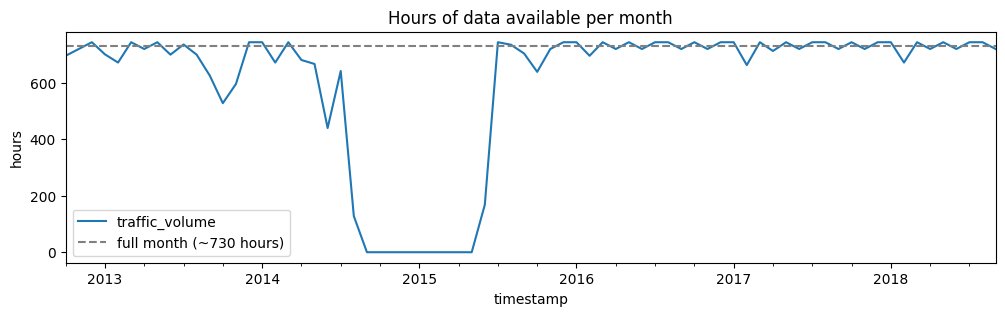

In [9]:
monthly = clean["traffic_volume"].resample("MS").count()
ax = monthly.plot(figsize=(12, 3))
ax.axhline(730, color="grey", linestyle="--", label="full month (~730 hours)")
ax.set_title("Hours of data available per month")
ax.set_ylabel("hours"); ax.legend()
ax.figure.savefig(f"{PROJECT}/figures/00_missing_by_month.png", dpi=150, bbox_inches="tight")
plt.show()

,count,mean,std,min,25%,50%,75%,max
traffic_volume,43623.0,3305.590056,1974.631920,0.00,1303.00,3460.0,4963.00,7280.00
temp_k,43623.0,281.126605,13.012692,243.39,271.74,282.2,292.02,310.07
rain_1h,43623.0,0.075779,0.752707,0.00,0.00,0.0,0.00,55.63
snow_1h,43623.0,0.000167,0.006490,0.00,0.00,0.0,0.00,0.51
clouds_all,43623.0,44.524815,38.647487,0.00,1.00,40.0,90.00,100.00


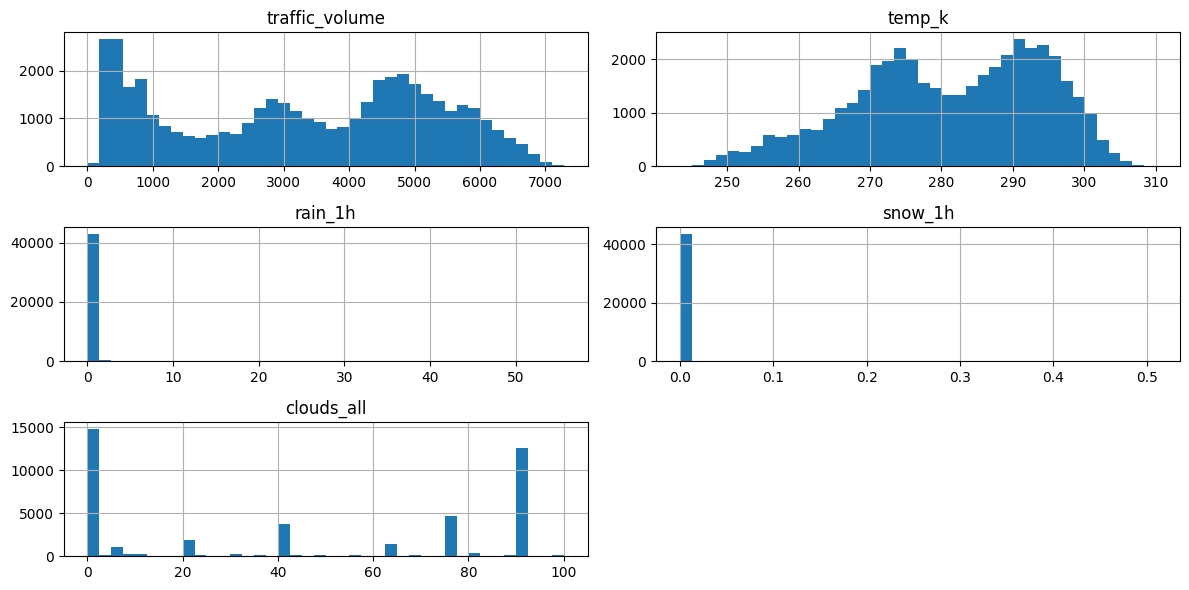

In [10]:
cols = ["traffic_volume", "temp_k", "rain_1h", "snow_1h", "clouds_all"]
display(clean[cols].describe().T)
clean[cols].hist(bins=40, figsize=(12, 6))
plt.tight_layout()
plt.savefig(f"{PROJECT}/figures/00_histograms.png", dpi=150, bbox_inches="tight")
plt.show()

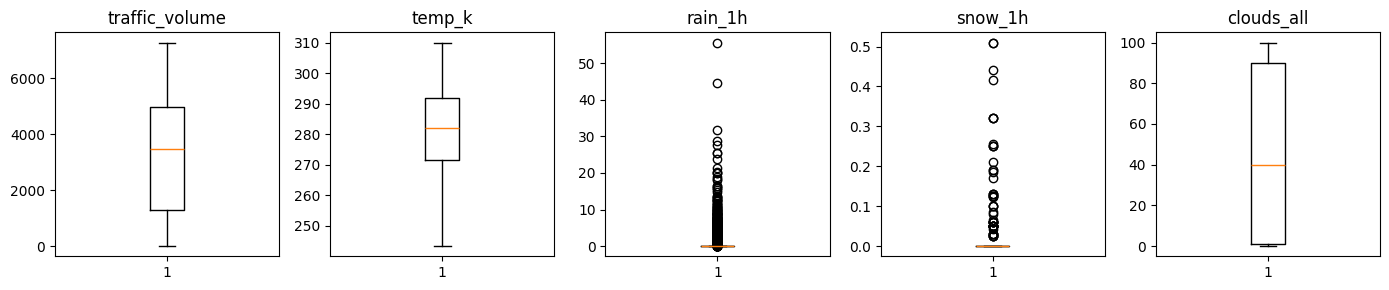

Share of hours with zero rain / snow:
 rain_1h    0.948857
snow_1h    0.998785
dtype: float64
traffic_volume == 0: 2
weather_main
Clouds          16103
Clear           14378
Rain             5097
Mist             3362
Snow             2562
Haze              860
Drizzle           563
Thunderstorm      470
Fog               212
Smoke              15
Squall              1
Name: count, dtype: int64


In [16]:
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
for ax, c in zip(axes, cols):
    ax.boxplot(clean[c]); ax.set_title(c)
plt.tight_layout(); plt.show()

print("Share of hours with zero rain / snow:\n", (clean[["rain_1h", "snow_1h"]] == 0).mean())
print("traffic_volume == 0:", (clean["traffic_volume"] == 0).sum())
print(clean["weather_main"].value_counts())

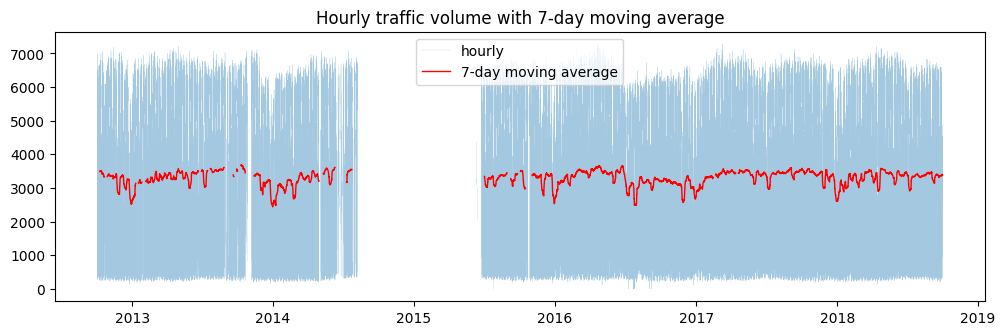

In [18]:
import os
os.makedirs(f"{PROJECT}/figures", exist_ok=True)

tv = clean["traffic_volume"].asfreq("h")     # gaps become NaN, so the plot breaks there
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(tv.index, tv, linewidth=0.2, alpha=0.4, label="hourly")
ax.plot(tv.index, tv.rolling(24*7, min_periods=24*7).mean(),
        color="red", linewidth=1, label="7-day moving average")
ax.set_title("Hourly traffic volume with 7-day moving average")
ax.legend()
fig.savefig(f"{PROJECT}/figures/01_full_series.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
print(clean[clean["traffic_volume"] == 0])

                    holiday  temp_k  rain_1h  snow_1h  clouds_all  \
timestamp                                                           
2016-07-23 18:00:00    None  296.68      0.0      0.0          40   
2016-07-23 23:00:00    None  295.90      0.0      0.0          90   

                    weather_main weather_description  traffic_volume  \
timestamp                                                              
2016-07-23 18:00:00         Rain          light rain               0   
2016-07-23 23:00:00         Haze                haze               0   

                     is_imputed  
timestamp                        
2016-07-23 18:00:00           0  
2016-07-23 23:00:00           0  


Question 1: Is there a long-term trend?

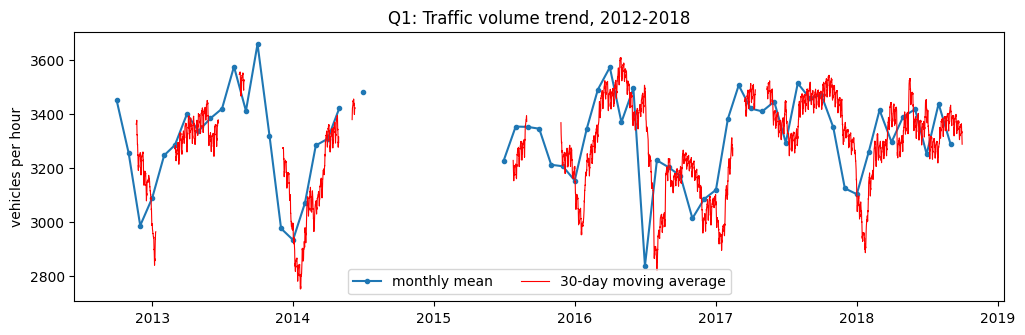

timestamp
2012    3227.0
2013    3335.0
2014    3272.0
2015    3285.0
2016    3247.0
2017    3375.0
2018    3319.0
Name: traffic_volume, dtype: float64


In [21]:
tv = clean["traffic_volume"].asfreq("h")
monthly = tv.resample("MS").mean().where(tv.resample("MS").count() >= 500)  # skip near-empty months
ma30 = tv.rolling(24*30, min_periods=24*30).mean()

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(monthly.index, monthly, marker="o", markersize=3, label="monthly mean")
ax.plot(ma30.index, ma30, color="red", linewidth=0.8, label="30-day moving average")
ax.set_title("Q1: Traffic volume trend, 2012-2018")
ax.set_ylabel("vehicles per hour"); ax.legend(loc="lower center", ncol=2)
fig.savefig(f"{PROJECT}/figures/02_trend.png", dpi=150, bbox_inches="tight")
plt.show()

print(clean["traffic_volume"].groupby(clean.index.year).mean().round(0))

No. Average traffic stays between about 3,230 and 3,375 vehicles per hour every year, so it doesn’t rise or fall over time. What we do see is a seasonal pattern: traffic dips in winter and is higher in other months. The missing period from August 2014 to June 2015 hides one winter, but traffic before and after it is at a similar level.

Question 2: Daily and weekly pattern

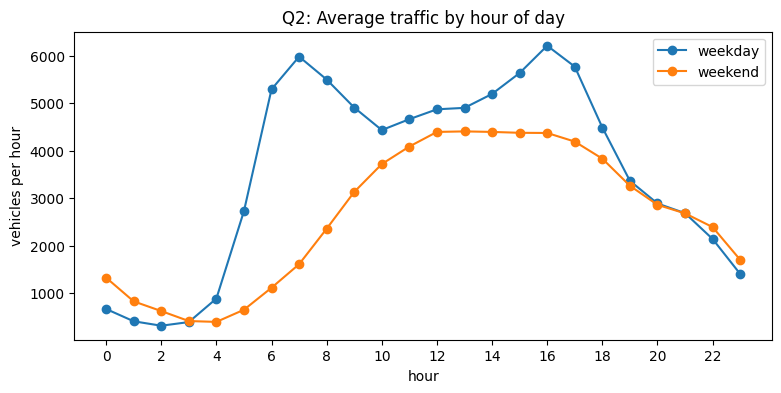

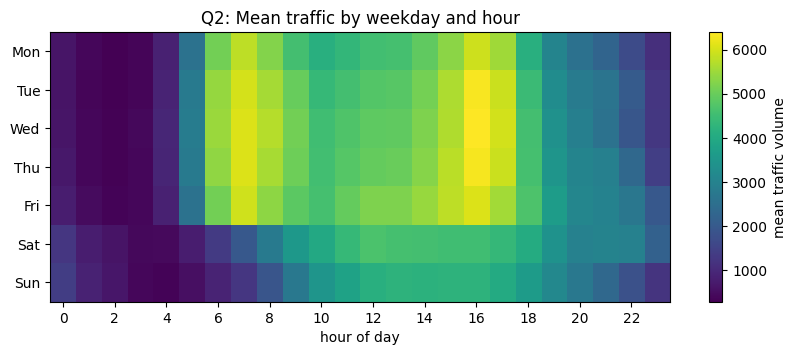

In [22]:
d = clean.copy()
d["hour"] = d.index.hour
d["is_weekend"] = d.index.dayofweek >= 5

prof = d.groupby(["hour", "is_weekend"])["traffic_volume"].mean().unstack()
prof.columns = ["weekday", "weekend"]
ax = prof.plot(figsize=(9, 4), marker="o")
ax.set_title("Q2: Average traffic by hour of day")
ax.set_ylabel("vehicles per hour"); ax.set_xticks(range(0, 24, 2))
ax.figure.savefig(f"{PROJECT}/figures/03_hourly_profile.png", dpi=150, bbox_inches="tight")
plt.show()

heat = d.pivot_table(index=d.index.dayofweek, columns="hour", values="traffic_volume", aggfunc="mean")
fig, ax = plt.subplots(figsize=(10, 3.5))
im = ax.imshow(heat, aspect="auto", cmap="viridis")
ax.set_yticks(range(7)); ax.set_yticklabels(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"])
ax.set_xticks(range(0, 24, 2)); ax.set_xticklabels(range(0, 24, 2))
ax.set_xlabel("hour of day"); ax.set_title("Q2: Mean traffic by weekday and hour")
fig.colorbar(im, ax=ax, label="mean traffic volume")
fig.savefig(f"{PROJECT}/figures/04_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

Yes, a strong one. On weekdays there are two rush-hour peaks, around 7am (about 6,000) and 4pm (about 6,200), and the quietest time is about 2am. Weekends have no rush-hour peaks and are flatter, with traffic building slowly to a plateau of about 4,400 in the afternoon

Question 3: Does traffic depend on its own past? (lagged features)

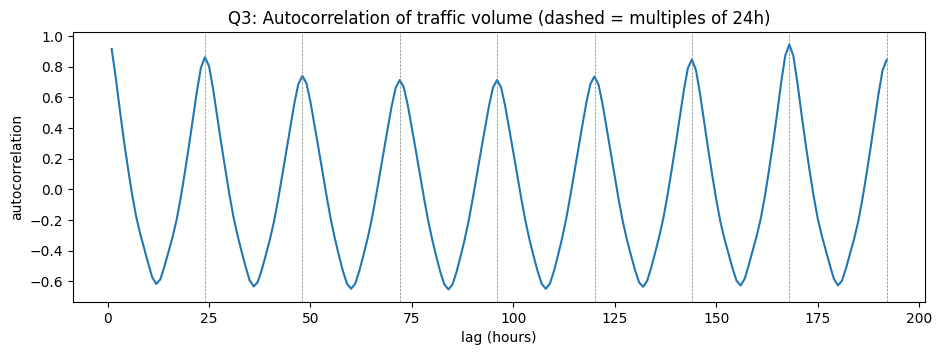

traffic_volume    1.000
lag_1             0.915
lag_24            0.862
lag_168           0.945
Name: traffic_volume, dtype: float64


In [23]:
tv = clean["traffic_volume"].asfreq("h")
lags = range(1, 24*8 + 1)
acf = [tv.autocorr(l) for l in lags]

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(lags, acf)
for k in range(1, 9):
    ax.axvline(24*k, color="grey", linestyle="--", linewidth=0.5)
ax.set_xlabel("lag (hours)"); ax.set_ylabel("autocorrelation")
ax.set_title("Q3: Autocorrelation of traffic volume (dashed = multiples of 24h)")
fig.savefig(f"{PROJECT}/figures/05_autocorrelation.png", dpi=150, bbox_inches="tight")
plt.show()

print(feat[["traffic_volume", "lag_1", "lag_24", "lag_168"]].corr()["traffic_volume"].round(3))

Yes. Traffic now is closely related to traffic one hour ago (0.915), 24 hours ago (0.862) and especially one week ago (0.945). The autocorrelation plot repeats every 24 hours, and the strongest peak is at 168 hours. So the same hour last week is the best single past value to use as a feature

Q4: Moving averages

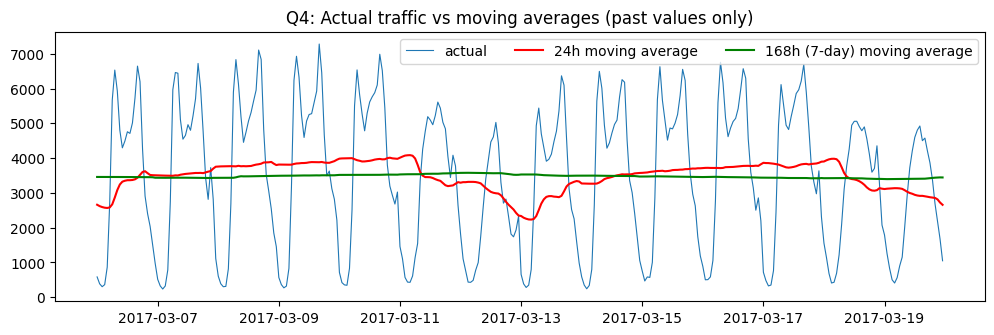

traffic_volume    1.000
ma_24             0.184
ma_168            0.087
Name: traffic_volume, dtype: float64

Mean absolute error as a naive predictor:
lag_1 578
lag_24 583
lag_168 354
ma_24 1710
ma_168 1721


In [24]:
f = feat.loc["2017-03-06":"2017-03-19"]          # two normal weeks
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(f.index, f["traffic_volume"], linewidth=0.8, label="actual")
ax.plot(f.index, f["ma_24"], color="red", label="24h moving average")
ax.plot(f.index, f["ma_168"], color="green", label="168h (7-day) moving average")
ax.set_title("Q4: Actual traffic vs moving averages (past values only)")
ax.legend(loc="upper right", ncol=3)
fig.savefig(f"{PROJECT}/figures/06_moving_averages.png", dpi=150, bbox_inches="tight")
plt.show()

print(feat[["traffic_volume", "ma_24", "ma_168"]].corr()["traffic_volume"].round(3))
print("\nMean absolute error as a naive predictor:")
for c in ["lag_1", "lag_24", "lag_168", "ma_24", "ma_168"]:
    print(c, round((feat["traffic_volume"] - feat[c]).abs().mean()))

They smooth out the noise and show the general level of traffic, but they can’t follow the daily ups and downs, so they’re weak predictors on their own (error of about 1,710 for the 24-hour average). Lag values do much better, and “same hour last week” is best, with an error of about 354. Moving averages are most useful as extra features that tell the model how busy things have been recently.

Q5: Weather and traffic

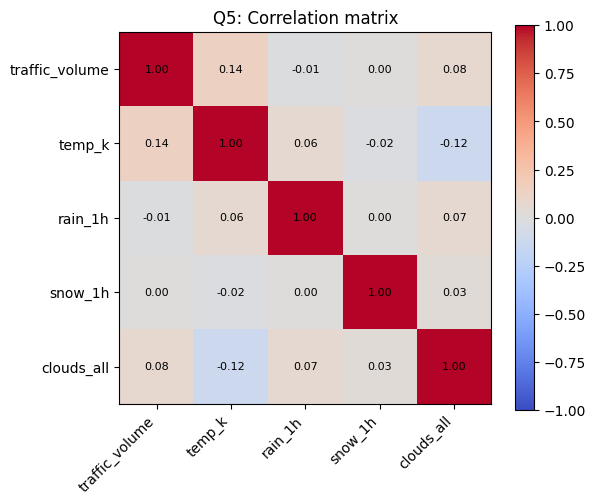

Correlation with traffic after removing the weekly pattern:
temp_k        0.168
rain_1h      -0.027
snow_1h      -0.018
clouds_all   -0.076
dtype: float64


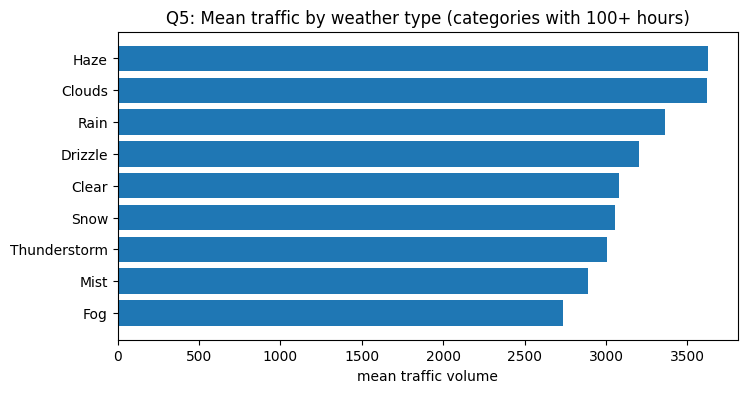

In [25]:
num = ["traffic_volume", "temp_k", "rain_1h", "snow_1h", "clouds_all"]
corr = clean[num].corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=45, ha="right")
ax.set_yticks(range(len(num))); ax.set_yticklabels(num)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax); ax.set_title("Q5: Correlation matrix")
fig.savefig(f"{PROJECT}/figures/07_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

# weather effect AFTER removing the normal hour-of-week pattern
base = clean.groupby([clean.index.dayofweek, clean.index.hour])["traffic_volume"].transform("mean")
resid = clean["traffic_volume"] - base
print("Correlation with traffic after removing the weekly pattern:")
print(clean[["temp_k", "rain_1h", "snow_1h", "clouds_all"]].corrwith(resid).round(3))

g = clean.groupby("weather_main")["traffic_volume"].agg(["mean", "count"])
g = g[g["count"] >= 100].sort_values("mean")
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(g.index, g["mean"]); ax.set_xlabel("mean traffic volume")
ax.set_title("Q5: Mean traffic by weather type (categories with 100+ hours)")
fig.savefig(f"{PROJECT}/figures/08_weather_bar.png", dpi=150, bbox_inches="tight")
plt.show()

Only weakly. Temperature has the strongest link (0.14, or 0.168 after removing the daily pattern), and cloud cover is smaller (0.08). Rain and snow have almost no effect, which makes sense because it rarely rains and almost never snows in this data. Temperature is therefore the most useful weather feature.

Q6: Holidays

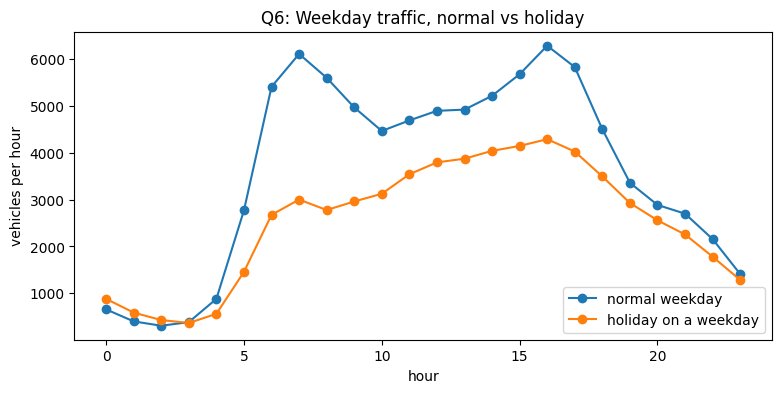

Holiday days in the data: 48
is_holiday
0    3604.0
1    2534.0
Name: traffic_volume, dtype: float64


In [26]:
wd = feat[feat["dayofweek"] < 5]                  # weekdays only, so weekends don't distort it
prof = wd.groupby(["hour", "is_holiday"])["traffic_volume"].mean().unstack()
prof.columns = ["normal weekday", "holiday on a weekday"]
ax = prof.plot(figsize=(9, 4), marker="o")
ax.set_title("Q6: Weekday traffic, normal vs holiday"); ax.set_ylabel("vehicles per hour")
ax.figure.savefig(f"{PROJECT}/figures/09_holiday.png", dpi=150, bbox_inches="tight")
plt.show()

print("Holiday days in the data:", feat[feat["is_holiday"] == 1].index.normalize().nunique())
print(wd.groupby("is_holiday")["traffic_volume"].mean().round(0))

Yes. On weekday holidays, traffic averages 2,534 vehicles per hour against 3,604 on a normal weekday, which is about 30% lower. The rush-hour peaks mostly disappear, so a holiday looks like a weekend. This supports using is_holiday as a feature, but there are only 48 holiday days.

In [3]:
import json, os, joblib
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

os.makedirs(f"{PROJECT}/models", exist_ok=True)

TARGET = "traffic_volume"
CAL_WEATHER = ["temp_k", "rain_1h", "clouds_all", "is_holiday", "hour", "dayofweek", "month"]
LAGS = ["lag_1", "lag_24", "lag_168", "ma_24", "ma_168"]
FEATURES = CAL_WEATHER + LAGS

n = len(feat)
train = feat.iloc[:int(n * 0.70)]
val   = feat.iloc[int(n * 0.70):int(n * 0.85)]
test  = feat.iloc[int(n * 0.85):]

for name, d in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:5s} {len(d):6d} rows  {d.index.min()} -> {d.index.max()}")

train  27590 rows  2012-10-09 09:00:00 -> 2017-05-26 06:00:00
val     5912 rows  2017-05-26 07:00:00 -> 2018-01-27 14:00:00
test    5913 rows  2018-01-27 15:00:00 -> 2018-09-30 23:00:00


In [4]:
tscv = TimeSeriesSplit(n_splits=3)
results = []
models = {}

def scores(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred)), mean_absolute_error(y_true, y_pred)

def log(exp, model, feats, params, pred_val, pred_test):
    rv, mv = scores(val[TARGET], pred_val)
    rt, mt = scores(test[TARGET], pred_test)
    results.append({"Exp": exp, "Model": model, "Features": feats, "Hyperparameters": params,
                    "Val RMSE": round(rv), "Val MAE": round(mv),
                    "Test RMSE": round(rt), "Test MAE": round(mt)})
    return pd.DataFrame(results)

def make_ridge(feats):
    cat = [c for c in ["hour", "dayofweek", "month"] if c in feats]
    num = [c for c in feats if c not in cat]
    prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat),
                              ("num", StandardScaler(), num)])
    return Pipeline([("prep", prep), ("model", Ridge())])

In [5]:
log(0, "Baseline: lag_168", "lag_168 only", "none",
    val["lag_168"], test["lag_168"])

,Exp,Model,Features,Hyperparameters,Val RMSE,Val MAE,Test RMSE,Test MAE
0,0,Baseline: lag_168,lag_168 only,none,657,344,623,320


In [6]:
gs1 = GridSearchCV(make_ridge(CAL_WEATHER), {"model__alpha": [0.1, 1, 10, 100]},
                   cv=tscv, scoring="neg_root_mean_squared_error")
gs1.fit(train[CAL_WEATHER], train[TARGET])
m1 = gs1.best_estimator_
models[1] = (m1, CAL_WEATHER)

log(1, "Ridge (no lags)", f"{len(CAL_WEATHER)} features", f"alpha={gs1.best_params_['model__alpha']}",
    m1.predict(val[CAL_WEATHER]), m1.predict(test[CAL_WEATHER]))

,Exp,Model,Features,Hyperparameters,Val RMSE,Val MAE,Test RMSE,Test MAE
0,0,Baseline: lag_168,lag_168 only,none,657,344,623,320
1,1,Ridge (no lags),7 features,alpha=10,799,599,760,565


In [7]:
gs2 = GridSearchCV(make_ridge(FEATURES), {"model__alpha": [0.1, 1, 10, 100]},
                   cv=tscv, scoring="neg_root_mean_squared_error")
gs2.fit(train[FEATURES], train[TARGET])
m2 = gs2.best_estimator_
models[2] = (m2, FEATURES)

log(2, "Ridge (with lags)", f"{len(FEATURES)} features", f"alpha={gs2.best_params_['model__alpha']}",
    m2.predict(val[FEATURES]), m2.predict(test[FEATURES]))

,Exp,Model,Features,Hyperparameters,Val RMSE,Val MAE,Test RMSE,Test MAE
0,0,Baseline: lag_168,lag_168 only,none,657,344,623,320
1,1,Ridge (no lags),7 features,alpha=10,799,599,760,565
2,2,Ridge (with lags),12 features,alpha=10,393,271,371,258


In [8]:
m3 = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
m3.fit(train[FEATURES], train[TARGET])
models[3] = (m3, FEATURES)

log(3, "Random Forest (default)", f"{len(FEATURES)} features", "n_estimators=100",
    m3.predict(val[FEATURES]), m3.predict(test[FEATURES]))

,Exp,Model,Features,Hyperparameters,Val RMSE,Val MAE,Test RMSE,Test MAE
0,0,Baseline: lag_168,lag_168 only,none,657,344,623,320
1,1,Ridge (no lags),7 features,alpha=10,799,599,760,565
2,2,Ridge (with lags),12 features,alpha=10,393,271,371,258
3,3,Random Forest (default),12 features,n_estimators=100,264,166,241,152


In [14]:
param_dist = {"n_estimators": [100, 200],
              "max_depth": [8, 12, 20, None],
              "min_samples_leaf": [1, 3, 5, 10],
              "max_features": [0.5, 1.0]}
rs = RandomizedSearchCV(RandomForestRegressor(random_state=42, n_jobs=-1), param_dist,
                        n_iter=8, cv=tscv, scoring="neg_root_mean_squared_error", random_state=42)
rs.fit(train[FEATURES], train[TARGET])
m4 = rs.best_estimator_
models[4] = (m4, FEATURES)
print(rs.best_params_)

log(4, "Random Forest (tuned)", f"{len(FEATURES)} features", str(rs.best_params_),
    m4.predict(val[FEATURES]), m4.predict(test[FEATURES]))

NameError: name 'RandomizedSearchCV' is not defined

In [10]:
table = pd.DataFrame(results)
display(table)
table.to_csv(f"{PROJECT}/models/experiment_table.csv", index=False)

best_exp = int(table[table["Exp"] > 0].sort_values("Val RMSE").iloc[0]["Exp"])   # chosen on validation
best_model, best_feats = models[best_exp]
print("Best by validation RMSE: experiment", best_exp)

joblib.dump(best_model, f"{PROJECT}/models/best_model.joblib")
with open(f"{PROJECT}/models/features.json", "w") as f:
    json.dump({"features": best_feats, "target": TARGET}, f)

,Exp,Model,Features,Hyperparameters,Val RMSE,Val MAE,Test RMSE,Test MAE
0,0,Baseline: lag_168,lag_168 only,none,657,344,623,320
1,1,Ridge (no lags),7 features,alpha=10,799,599,760,565
2,2,Ridge (with lags),12 features,alpha=10,393,271,371,258
3,3,Random Forest (default),12 features,n_estimators=100,264,166,241,152
4,4,Random Forest (tuned),12 features,"{'n_estimators': 100, 'min_samples_leaf': 1, '...",259,167,236,153


Best by validation RMSE: experiment 4


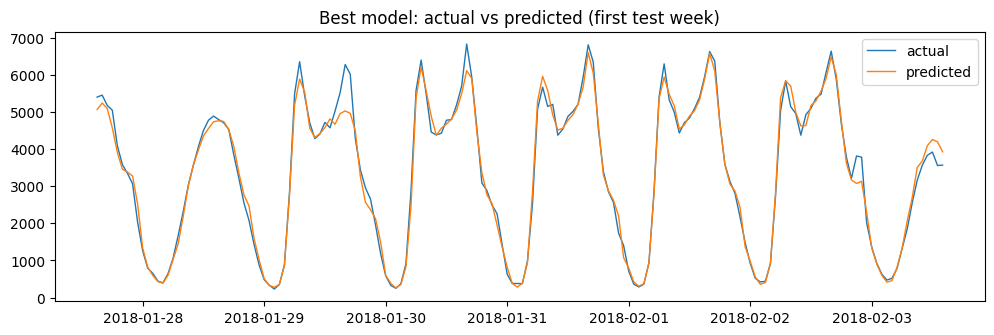

In [11]:
wk = test.iloc[:24 * 7]
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(wk.index, wk[TARGET], label="actual", linewidth=1)
ax.plot(wk.index, best_model.predict(wk[best_feats]), label="predicted", linewidth=1)
ax.set_title("Best model: actual vs predicted (first test week)"); ax.legend()
fig.savefig(f"{PROJECT}/figures/10_predictions.png", dpi=150, bbox_inches="tight")
plt.show()

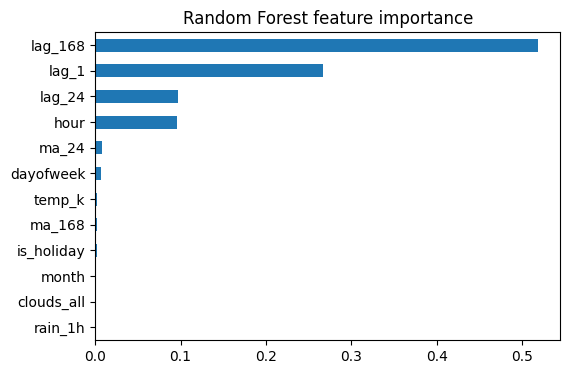

In [12]:
if hasattr(best_model, "feature_importances_"):
    imp = pd.Series(best_model.feature_importances_, index=best_feats).sort_values()
    ax = imp.plot.barh(figsize=(6, 4), title="Random Forest feature importance")
    ax.figure.savefig(f"{PROJECT}/figures/11_importance.png", dpi=150, bbox_inches="tight")
    plt.show()

In [15]:
joblib.dump(best_model, f"{PROJECT}/models/best_model.joblib", compress=3)

size_mb = os.path.getsize(f"{PROJECT}/models/best_model.joblib") / 1e6
print(f"model file size: {size_mb:.1f} MB")

m = joblib.load(f"{PROJECT}/models/best_model.joblib")
print(m.predict(test[best_feats].head(3)))

NameError: name 'joblib' is not defined